# Frozen ResNet18 baseline

We use ResNet18 with ImageNet weights, freeze its backbone, and train only a five-output classification head. Training uses BCEWithLogitsLoss, AdamW (lr=0.001), five epochs, 224x224 images, and horizontal flips. Because this is multilabel classification, each output uses sigmoid, not softmax.

In [1]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

root = Path.cwd()
if not (root / "data/train.csv").exists():
    root = root.parent

labels = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]

df = pd.read_csv(root / "data/train.csv")
folds = pd.read_csv(root / "folds.csv")

df = df.merge(folds, on="image_id", validate="one_to_one")

train_df = df[df["fold"] != 0].reset_index(drop=True)
val_df = df[df["fold"] == 0].reset_index(drop=True)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Train:", len(train_df))
print("Validation:", len(val_df))

Train: 9808
Validation: 2452


In [2]:
class CatsDogsDataset(Dataset):
    def __init__(self, df, folder, transform):
        self.df = df
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        path = self.folder / f"{row['image_id']}.jpg"

        with Image.open(path) as img:
            image = self.transform(img.convert("RGB"))

        target = torch.tensor(
            row[labels].to_numpy(dtype="float32")
        )

        return image, target


train_data = CatsDogsDataset(
    train_df, root / "data/train", train_transform
)

val_data = CatsDogsDataset(
    val_df, root / "data/train", val_transform
)

train_loader = DataLoader(
    train_data, batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_data, batch_size=32, shuffle=False, num_workers=2
)

images, targets = next(iter(train_loader))

print("Images:", images.shape)
print("Targets:", targets.shape)

Images: torch.Size([32, 3, 224, 224])
Targets: torch.Size([32, 5])


In [8]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

model = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 5)
model = model.to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.fc.parameters(), lr=0.001)

print("Device:", device)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

Device: cuda
Trainable parameters: 2565


In [6]:
import numpy as np
from sklearn.metrics import f1_score

epochs = 5
best_f1 = -1
history = []

(root / "checkpoints").mkdir(exist_ok=True)

for epoch in range(epochs):
    # Frozen backbone: keep BatchNorm statistics fixed
    model.eval()

    train_loss = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(x)

    train_loss /= len(train_data)

    # Validation
    model.eval()
    val_loss = 0
    predictions = []
    targets = []

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            val_loss += loss.item() * len(x)
            predictions.append(torch.sigmoid(logits).cpu().numpy())
            targets.append(y.cpu().numpy())

    val_loss /= len(val_data)

    probs = np.concatenate(predictions)
    y_true = np.concatenate(targets)
    y_pred = (probs >= 0.5).astype(int)

    f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    history.append([epoch + 1, train_loss, val_loss, f1])

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Macro-F1: {f1:.4f}"
    )

    if f1 > best_f1:
        best_f1 = f1
        torch.save(
            model.state_dict(),
            root / "checkpoints/baseline_resnet18.pt"
        )

print("\nBest validation Macro-F1:", round(best_f1, 4))

Epoch 1/5 | Train loss: 0.0896 | Val loss: 0.0487 | Macro-F1: 0.3858
Epoch 2/5 | Train loss: 0.0441 | Val loss: 0.0395 | Macro-F1: 0.3872
Epoch 3/5 | Train loss: 0.0357 | Val loss: 0.0338 | Macro-F1: 0.4618
Epoch 4/5 | Train loss: 0.0312 | Val loss: 0.0308 | Macro-F1: 0.6148
Epoch 5/5 | Train loss: 0.0286 | Val loss: 0.0288 | Macro-F1: 0.6746

Best validation Macro-F1: 0.6746


,Epoch,Train Loss,Val Loss,Macro-F1
0,1,0.089584,0.048657,0.385785
1,2,0.044126,0.039482,0.387227
2,3,0.035697,0.033773,0.461849
3,4,0.031167,0.030815,0.614790
4,5,0.028595,0.028790,0.674623


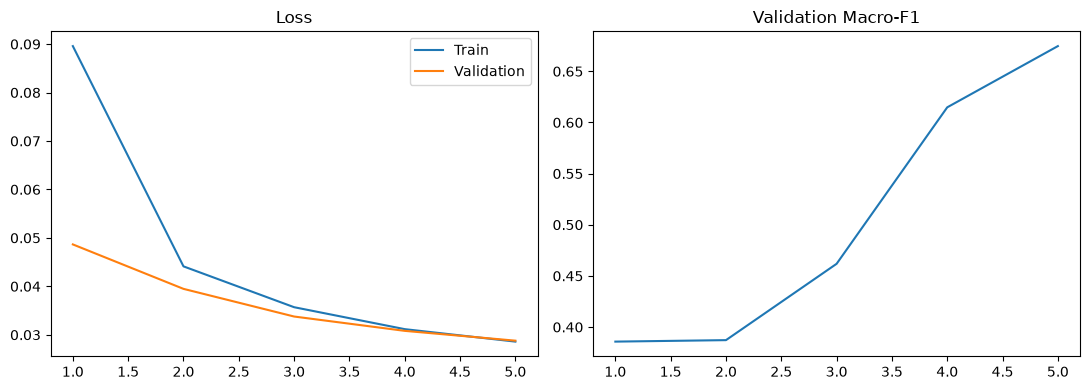

In [10]:
import matplotlib.pyplot as plt
results = pd.DataFrame(
    history,
    columns=["Epoch", "Train Loss", "Val Loss", "Macro-F1"]
)

display(results)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(results["Epoch"], results["Train Loss"], label="Train")
axes[0].plot(results["Epoch"], results["Val Loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(results["Epoch"], results["Macro-F1"])
axes[1].set_title("Validation Macro-F1")

plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score

scores = pd.DataFrame({
    "Class": labels,
    "Precision": precision_score(y_true, y_pred, average=None, zero_division=0),
    "Recall": recall_score(y_true, y_pred, average=None, zero_division=0),
    "F1": f1_score(y_true, y_pred, average=None, zero_division=0),
    "Support": y_true.sum(axis=0).astype(int)
})

display(scores.round(3))

,Class,Precision,Recall,F1,Support
0,Cat,0.985,0.971,0.978,1015
1,Dog,0.977,0.957,0.967,1005
2,Moris,1.000,0.545,0.706,11
3,Motya,1.000,0.125,0.222,8
4,Biatrix,1.000,0.333,0.500,9


In [12]:
thresholds = np.arange(0.1, 0.81, 0.05)
rows = []

for i, cls in enumerate(labels):
    scores = []

    for t in thresholds:
        pred = (probs[:, i] >= t).astype(int)
        f1 = f1_score(y_true[:, i], pred, zero_division=0)
        scores.append(f1)

    best_idx = np.argmax(scores)

    rows.append({
        "Class": cls,
        "F1 at 0.5": f1_score(
            y_true[:, i],
            (probs[:, i] >= 0.5).astype(int),
            zero_division=0
        ),
        "Best threshold": round(thresholds[best_idx], 2),
        "Best F1": scores[best_idx]
    })

threshold_results = pd.DataFrame(rows)

display(threshold_results.round(3))

print("Original Macro-F1:",
      round(f1_score(y_true, probs >= 0.5, average="macro"), 4))

print("Optimized Macro-F1:",
      round(threshold_results["Best F1"].mean(), 4))


,Class,F1 at 0.5,Best threshold,Best F1
0,Cat,0.978,0.45,0.979
1,Dog,0.967,0.40,0.971
2,Moris,0.706,0.20,0.833
3,Motya,0.222,0.20,0.667
4,Biatrix,0.500,0.20,0.737


Original Macro-F1: 0.6746
Optimized Macro-F1: 0.8373


In [13]:
from tqdm.auto import tqdm

class TestImages(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids.tolist()

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        path = root / "data/test" / f"{image_id}.jpg"

        with Image.open(path) as img:
            image = val_transform(img.convert("RGB"))

        return image


submission = pd.read_csv(root / "data/sample_submission.csv")

test_data = TestImages(submission["image_id"])
test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# Load best checkpoint
model.load_state_dict(
    torch.load(
        root / "checkpoints/baseline_resnet18.pt",
        map_location=device,
        weights_only=True
    )
)

model.eval()
test_probs = []

with torch.no_grad():
    for x in tqdm(test_loader):
        x = x.to(device)
        logits = model(x)
        test_probs.append(torch.sigmoid(logits).cpu().numpy())

test_probs = np.concatenate(test_probs)

assert test_probs.shape == (len(submission), 5)

submission[labels] = (test_probs >= 0.5).astype(int)

(root / "outputs").mkdir(exist_ok=True)
submission.to_csv(root / "outputs/resnet18_baseline.csv", index=False)

print("Saved:", submission.shape)
display(submission.head())

/home/dmytro/Завантажене/ai301-assignment-2-cnn/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 292/292 [00:30<00:00,  9.42it/s]

Saved: (18673, 6)


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24,0,0,0,0,0
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c,0,1,0,0,0
2,ac89f642faef21c92d622d882943e9065600354a,0,0,0,0,0
3,7245e7046ae54da95dbddc24ae814b3c61cc6237,1,0,0,0,0
4,d2b76179615de57b54cb00d094fba50810d96127,1,0,0,0,0


## Five-fold cross-validation

Each model is trained on four folds and evaluated on the remaining fold. OOF predictions are saved for all training images. The single-fold baseline and this CV experiment are separate training runs and can give different scores.

In [14]:
from torch.utils.data import DataLoader
from torchvision import models
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

oof_probs = np.zeros((len(df), 5))
fold_scores = []

for fold in range(5):
    print(f"\n--- Fold {fold} ---")

    train_idx = df.index[df["fold"] != fold]
    val_idx = df.index[df["fold"] == fold]

    train_data = CatsDogsDataset(
        df.loc[train_idx],
        root / "data/train",
        train_transform
    )

    val_data = CatsDogsDataset(
        df.loc[val_idx],
        root / "data/train",
        val_transform
    )

    train_loader = DataLoader(
        train_data, batch_size=32, shuffle=True, num_workers=2
    )
    val_loader = DataLoader(
        val_data, batch_size=32, shuffle=False, num_workers=2
    )

    torch.manual_seed(42 + fold)

    model = models.resnet18(
        weights=models.ResNet18_Weights.IMAGENET1K_V1
    )

    for p in model.parameters():
        p.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, 5)
    model = model.to(device)

    optimizer = torch.optim.AdamW(model.fc.parameters(), lr=0.001)
    criterion = nn.BCEWithLogitsLoss()

    # Fixed 5 epochs, same as our first baseline
    for epoch in range(5):
        model.eval()
        total_loss = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(x)

        print(f"Epoch {epoch + 1}/5 - Loss: {total_loss / len(train_data):.4f}")

    # Validation predictions
    model.eval()
    predictions = []

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            p = torch.sigmoid(model(x))
            predictions.append(p.cpu().numpy())

    predictions = np.concatenate(predictions)
    oof_probs[val_idx] = predictions

    y_true_fold = df.loc[val_idx, labels].to_numpy()

    score = f1_score(
        y_true_fold,
        predictions >= 0.5,
        average="macro",
        zero_division=0
    )

    fold_scores.append(score)
    print(f"Fold {fold} Macro-F1: {score:.4f}")

    torch.save(
        model.state_dict(),
        root / f"checkpoints/resnet18_fold{fold}.pt"
    )

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nMean CV:", round(np.mean(fold_scores), 4))
print("Std CV:", round(np.std(fold_scores), 4))

y_true_all = df[labels].to_numpy()
oof_score = f1_score(
    y_true_all,
    oof_probs >= 0.5,
    average="macro",
    zero_division=0
)
print("OOF Macro-F1:", round(oof_score, 4))

oof = df[["image_id", "fold"]].copy()
oof[labels] = oof_probs
oof.to_csv(root / "outputs/resnet18_oof.csv", index=False)


--- Fold 0 ---
Epoch 1/5 - Loss: 0.0896
Epoch 2/5 - Loss: 0.0429
Epoch 3/5 - Loss: 0.0354
Epoch 4/5 - Loss: 0.0313
Epoch 5/5 - Loss: 0.0285
Fold 0 Macro-F1: 0.7572

--- Fold 1 ---
Epoch 1/5 - Loss: 0.0884
Epoch 2/5 - Loss: 0.0429
Epoch 3/5 - Loss: 0.0342
Epoch 4/5 - Loss: 0.0300
Epoch 5/5 - Loss: 0.0276
Fold 1 Macro-F1: 0.6376

--- Fold 2 ---
Epoch 1/5 - Loss: 0.0864
Epoch 2/5 - Loss: 0.0433
Epoch 3/5 - Loss: 0.0360
Epoch 4/5 - Loss: 0.0315
Epoch 5/5 - Loss: 0.0285
Fold 2 Macro-F1: 0.6406

--- Fold 3 ---
Epoch 1/5 - Loss: 0.0810
Epoch 2/5 - Loss: 0.0417
Epoch 3/5 - Loss: 0.0346
Epoch 4/5 - Loss: 0.0293
Epoch 5/5 - Loss: 0.0270
Fold 3 Macro-F1: 0.5400

--- Fold 4 ---
Epoch 1/5 - Loss: 0.0822
Epoch 2/5 - Loss: 0.0410
Epoch 3/5 - Loss: 0.0332
Epoch 4/5 - Loss: 0.0297
Epoch 5/5 - Loss: 0.0271
Fold 4 Macro-F1: 0.6720

Mean CV: 0.6495
Std CV: 0.0697
OOF Macro-F1: 0.663


## Threshold check

Thresholds are selected using OOF predictions from the other four folds, then applied to the held-out fold. This is a useful check, but **not fully nested validation**: models producing the other-fold OOF predictions were partly trained on the evaluated fold. The tuned score may therefore be optimistic.

In [15]:
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

oof = pd.read_csv(root / "outputs/resnet18_oof.csv")

# Join labels and OOF predictions
data = df[["image_id", "fold"] + labels].merge(
    oof[["image_id"] + labels].rename(
        columns={c: "prob_" + c for c in labels}
    ),
    on="image_id",
    validate="one_to_one"
)

y = data[labels].to_numpy()
probs = data[["prob_" + c for c in labels]].to_numpy()
folds = data["fold"].to_numpy()

threshold_grid = np.arange(0.05, 0.81, 0.05)

new_pred = np.zeros_like(y)
fold_results = []
all_thresholds = []

for fold in range(5):
    train_mask = folds != fold
    val_mask = folds == fold

    best_thresholds = []

    for i, cls in enumerate(labels):
        scores = []

        for t in threshold_grid:
            pred = (probs[train_mask, i] >= t).astype(int)
            score = f1_score(y[train_mask, i], pred, zero_division=0)
            scores.append(score)

        best_score = max(scores)
        candidates = np.where(np.isclose(scores, best_score))[0]

        # Prefer threshold closest to 0.5 when scores are equal
        best_idx = min(
            candidates,
            key=lambda j: abs(threshold_grid[j] - 0.5)
        )

        best_thresholds.append(threshold_grid[best_idx])

    best_thresholds = np.array(best_thresholds)
    all_thresholds.append(best_thresholds)

    new_pred[val_mask] = (
        probs[val_mask] >= best_thresholds
    ).astype(int)

    original = f1_score(
        y[val_mask],
        probs[val_mask] >= 0.5,
        average="macro",
        zero_division=0
    )

    optimized = f1_score(
        y[val_mask],
        new_pred[val_mask],
        average="macro",
        zero_division=0
    )

    fold_results.append([fold, original, optimized])

results = pd.DataFrame(
    fold_results,
    columns=["Fold", "F1 original", "F1 tuned"]
)

print("Per-fold results:")
display(results.round(4))

print("Thresholds selected for each fold:")
display(pd.DataFrame(all_thresholds, columns=labels).round(2))

print("Per-class F1:")
display(pd.DataFrame({
    "Class": labels,
    "Original": f1_score(y, probs >= 0.5, average=None),
    "Tuned": f1_score(y, new_pred, average=None)
}).round(4))

print("Original OOF:", round(
    f1_score(y, probs >= 0.5, average="macro"), 4
))

print("Tuned OOF:", round(
    f1_score(y, new_pred, average="macro"), 4
))

Per-fold results:


,Fold,F1 original,F1 tuned
0,0,0.7572,0.7318
1,1,0.6376,0.7993
2,2,0.6406,0.7830
3,3,0.5400,0.7254
4,4,0.6720,0.7174


Thresholds selected for each fold:


,Cat,Dog,Moris,Motya,Biatrix
0,0.40,0.70,0.15,0.15,0.2
1,0.40,0.70,0.25,0.15,0.2
2,0.35,0.70,0.25,0.20,0.2
3,0.40,0.55,0.35,0.15,0.2
4,0.40,0.55,0.25,0.20,0.2


Per-class F1:


,Class,Original,Tuned
0,Cat,0.9729,0.9742
1,Dog,0.9676,0.9671
2,Moris,0.5610,0.6364
3,Motya,0.3137,0.5479
4,Biatrix,0.5000,0.6753


Original OOF: 0.663
Tuned OOF: 0.7602


In [16]:
thresholds = np.array([0.40, 0.70, 0.25, 0.15, 0.20])

# Probabilities from the previous fold 0 test inference
assert test_probs.shape == (18673, 5)

submission = pd.read_csv(root / "data/sample_submission.csv")
submission[labels] = (test_probs >= thresholds).astype(int)

submission.to_csv(
    root / "outputs/resnet18_tuned.csv",
    index=False
)

print("Saved:", submission.shape)
print("Positive predictions:")
print(submission[labels].sum())

Saved: (18673, 6)
Positive predictions:
Cat        7790
Dog        7230
Moris       117
Motya        70
Biatrix     117
dtype: int64


## Results summary

| Experiment | Macro-F1 |
|---|---:|
| 5-fold CV mean (threshold 0.5) | 0.6495 |
| OOF (threshold 0.5) | 0.6630 |
| OOF (fold-wise tuned thresholds) | 0.7602 |
| Kaggle Public LB, threshold 0.5 | 0.62666 |
| Kaggle Public LB, tuned thresholds | **0.78690** |

The chosen thresholds were Cat 0.40, Dog 0.70, Moris 0.25, Motya 0.15, Biatrix 0.20 (medians of fold-wise selections). Tuning mainly improved the rare classes. Both Kaggle submissions used the same **single fold-0 baseline model**, not a five-model ensemble. Public LB is only a partial test-set score, so it should not replace cross-validation.